In [1]:
from pathlib import Path
import sys

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in [start, *start.parents]:
        if (path / "src").is_dir() and (path / "notebooks").is_dir():
            return path
    raise RuntimeError("Could not find project root containing src/ and notebooks/")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\study\Code\python-studies\nanoparticle-diffusion-104337


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
k_B = 1.380649e-23

temperature = 310

viscosity = 0.001

radius = 50e-9

D = (k_B * temperature) / (6 * np.pi * viscosity * radius)

dt = 0.01

step_size = np.sqrt(2 * D * dt)

In [4]:
particles = 100

steps = 1000

x = np.zeros((particles, steps))

y = np.zeros((particles, steps))

np.random.seed(42)

In [5]:
for p in range(particles):

    for i in range(1, steps):

        dx = np.random.normal(0, step_size)
        dy = np.random.normal(0, step_size)

        x[p, i] = x[p, i-1] + dx
        y[p, i] = y[p, i-1] + dy

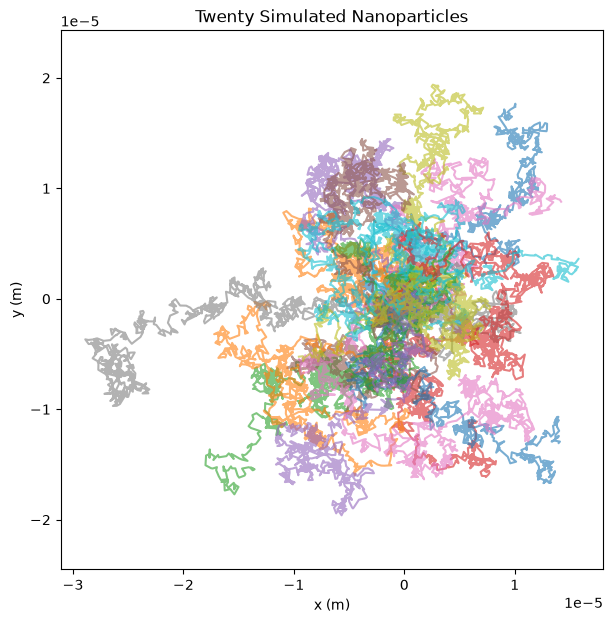

In [6]:
plt.figure(figsize=(7,7))

for p in range(20):
    plt.plot(x[p], y[p], alpha=0.6)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Twenty Simulated Nanoparticles")

plt.axis("equal")

plt.show()

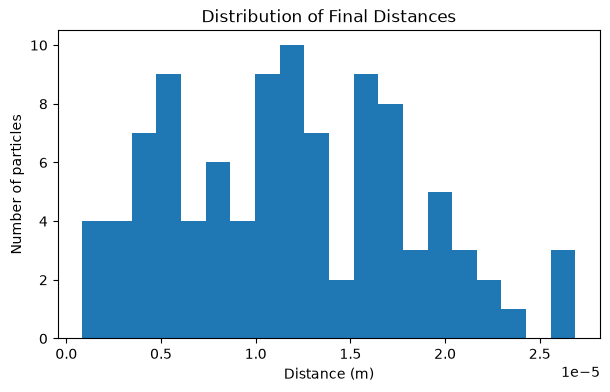

In [7]:
final_distance = np.sqrt(x[:, -1]**2 + y[:, -1]**2)

plt.figure(figsize=(7,4))

plt.hist(final_distance, bins=20)

plt.xlabel("Distance (m)")
plt.ylabel("Number of particles")

plt.title("Distribution of Final Distances")

plt.show()

In [8]:
print("Mean distance:", np.mean(final_distance))
print("Standard deviation:", np.std(final_distance))

Mean distance: 1.1821326469905093e-05
Standard deviation: 6.197496139500975e-06
